In [3]:
%pip install seaborn scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats
print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [12]:
from sklearn.model_selection import train_test_split
df = pd.read_csv('employee_performance.csv')
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
df.head()

Dataset Shape: (500, 10)

First 5 Records:


,Employee_ID,Age,Gender,Department,Experience_Years,Hours_Worked_Per_Week,Training_Score,Job_Satisfaction,Projects_Completed,Performance
0,1,50,Female,Finance,25,58,70,5,10,Average
1,2,36,Female,Operations,7,51,57,3,4,Poor
2,3,29,Male,IT,4,44,95,9,8,Poor
3,4,42,Male,Finance,8,44,89,5,18,Average
4,5,40,Male,Sales,20,58,95,5,14,Average


In [13]:
print("----Missing Values Count----")
print(df.isnull().sum())

----Missing Values Count----
Employee_ID              0
Age                      0
Gender                   0
Department               0
Experience_Years         0
Hours_Worked_Per_Week    0
Training_Score           0
Job_Satisfaction         0
Projects_Completed       0
Performance              0
dtype: int64


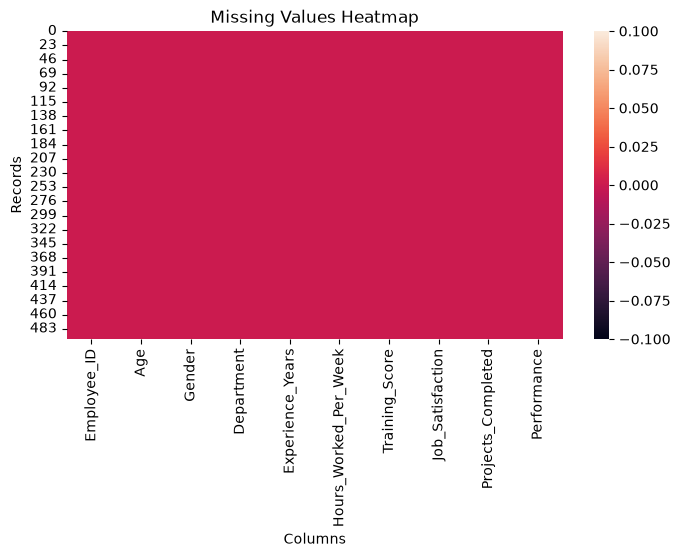

In [14]:
plt.figure(figsize=(8,4))
sns.heatmap(df.isnull())
plt.title("Missing Values Heatmap");
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

In [15]:
print("\nDuplicate Rows Found:", df.duplicated().sum())
df = df.drop_duplicates()
print("Dataset shape after dropping duplicates:", df.shape)


Duplicate Rows Found: 0
Dataset shape after dropping duplicates: (500, 10)


In [19]:
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['str']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print("\nMissing values after handling:\n", df.isnull().sum())


Missing values after handling:
 Employee_ID              0
Age                      0
Gender                   0
Department               0
Experience_Years         0
Hours_Worked_Per_Week    0
Training_Score           0
Job_Satisfaction         0
Projects_Completed       0
Performance              0
dtype: int64


In [20]:
X = df.drop(columns=['Employee_ID','Performance'])
y = df["Performance"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training Set Features Shape: ",X_train.shape)
print("Testing Set Features Shape: ",X_test.shape)
print("Training Set Target Shape: ",y_train.shape)
print("Testing Set Target Shape: ",y_test.shape)

Training Set Features Shape:  (400, 8)
Testing Set Features Shape:  (100, 8)
Training Set Target Shape:  (400,)
Testing Set Target Shape:  (100,)


Correlation Matrix:                    Experience_Years  Training_Score  Performance_Num
Experience_Years          1.000000        0.056055         0.706885
Training_Score            0.056055        1.000000         0.262942
Performance_Num           0.706885        0.262942         1.000000


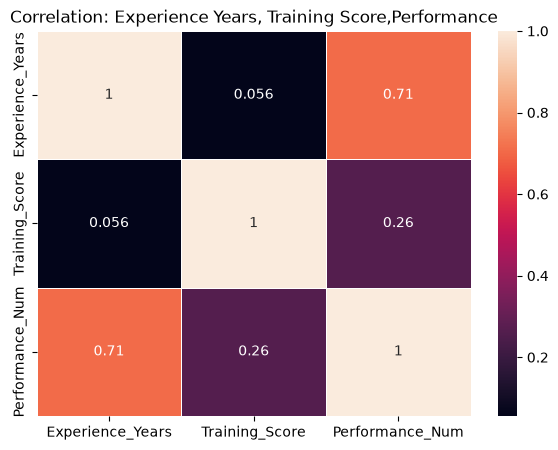

In [21]:
perf_order = {"Poor":1,"Average":2,"Good":3,"Excellent":4}
df["Performance_Num"] = df['Performance'].map(perf_order)

corr_cols = ["Experience_Years","Training_Score","Performance_Num"]
corr_matrix = df[corr_cols].corr()
print("Correlation Matrix: ",corr_matrix)

plt.figure(figsize=(7,5))
sns.heatmap(corr_matrix,annot=True,linewidths=0.5)
plt.title("Correlation: Experience Years, Training Score,Performance")
plt.show()

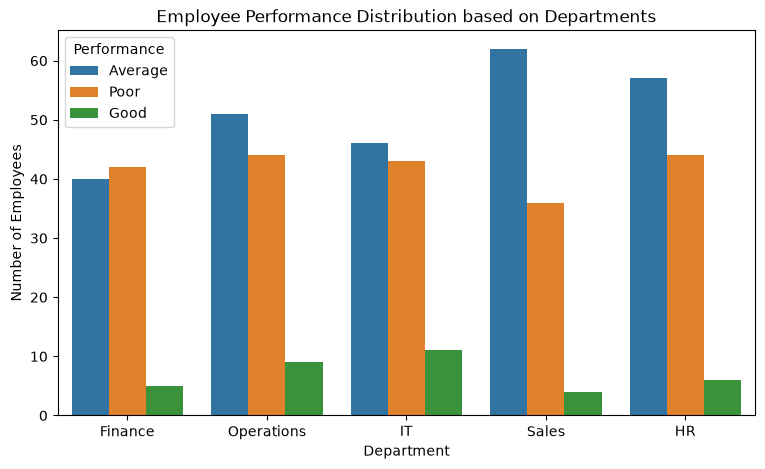

In [27]:
plt.figure(figsize=(9,5))
sns.countplot(data=df,x='Department',hue='Performance')
plt.title("Employee Performance Distribution based on Departments")
plt.xlabel("Department");
plt.ylabel("Number of Employees");
plt.show()

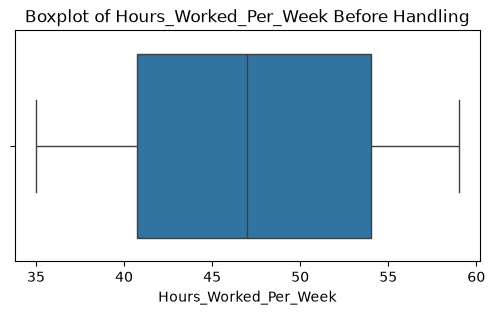

In [30]:
outlier_col = 'Hours_Worked_Per_Week'
plt.figure(figsize=(6,3))
sns.boxplot(x=df[outlier_col])
plt.title(f"Boxplot of {outlier_col} Before Handling")
plt.xlabel(outlier_col)
plt.show()

In [31]:
Q1 = df[outlier_col].quantile(0.25)
Q3 = df[outlier_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1: ",Q1,", Q3: ",Q3,", IQR: ",IQR)
print("Lower bound: ",lower_bound,"Upper bound: ",upper_bound)

Q1:  40.75 , Q3:  54.0 , IQR:  13.25
Lower bound:  20.875 Upper bound:  73.875


In [36]:
outliers = df[(df[outlier_col] < lower_bound) | (df[outlier_col] > upper_bound)]
print(f"Total Outliers Detected in {outlier_col}:{len(outliers)}")

Total Outliers Detected in Hours_Worked_Per_Week:0


In [37]:
df_clean = df[(df[outlier_col] >= lower_bound) & (df[outlier_col] <= upper_bound)].copy()
print(f"Rows Before: {len(df)} and Rows After: {len(df_clean)}")

Rows Before: 500 and Rows After: 500


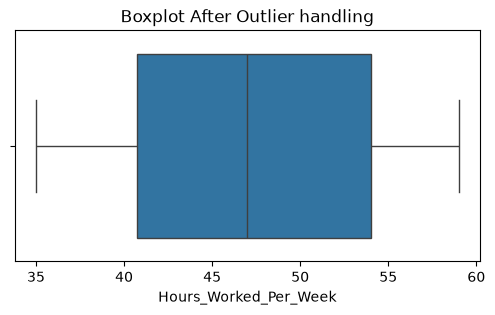

In [38]:
plt.figure(figsize=(6,3))
sns.boxplot(x=df_clean[outlier_col])
plt.title(f"Boxplot After Outlier handling")
plt.xlabel(outlier_col)
plt.show()

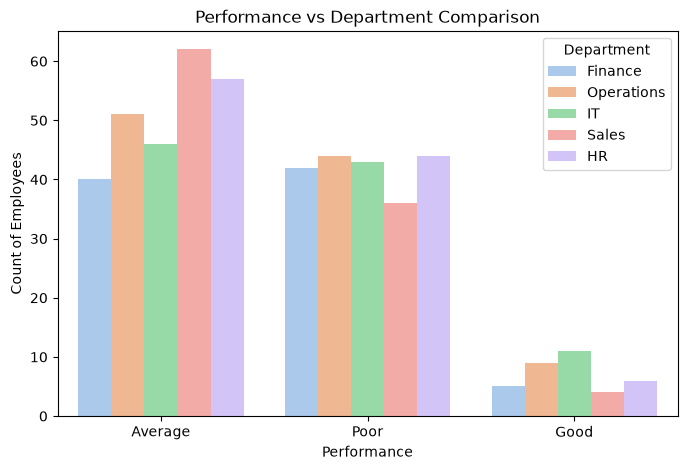

In [40]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_clean,x="Performance", hue="Department",palette='pastel')
plt.title("Performance vs Department Comparison")
plt.xlabel("Performance")
plt.ylabel("Count of Employees")
plt.show()

In [41]:
def categorize_tier(perf):
    if perf in ["Good","Excellent"]:
        return 'High Performer'
    else:
        return 'Low / Average Performer'
df['Performer_cat'] = df['Performance'].apply(categorize_tier)
tier_counts = df['Performer_cat'].value_counts()
print("Performer Category counts: ",tier_counts)

Performer Category counts:  Performer_cat
Low / Average Performer    465
High Performer              35
Name: count, dtype: int64


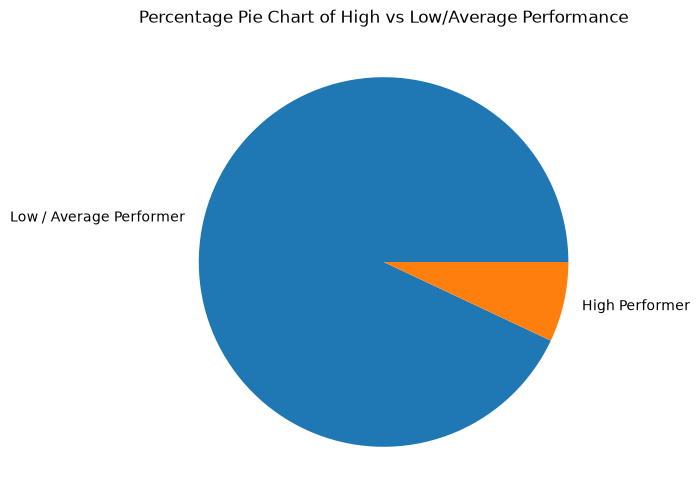

In [43]:
plt.figure(figsize=(6,6))
plt.pie(tier_counts,labels=tier_counts.index)
plt.title("Percentage Pie Chart of High vs Low/Average Performance")
plt.show()

Model Accuracy is:  0.9
Classfication Report:                precision    recall  f1-score   support

     Average       0.88      0.94      0.91        53
        Good       1.00      0.25      0.40         8
        Poor       0.93      0.97      0.95        39

    accuracy                           0.90       100
   macro avg       0.93      0.72      0.75       100
weighted avg       0.91      0.90      0.88       100



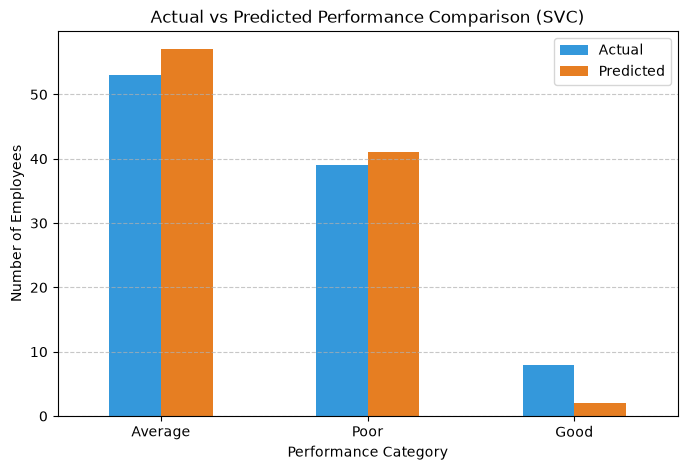

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

features = [
    'Age', 'Gender', 'Department', 'Experience_Years', 
    'Hours_Worked_Per_Week', 'Training_Score', 
    'Job_Satisfaction', 'Projects_Completed'
]
X = df[features].copy()
y = df['Performance']

le = LabelEncoder()
for col in ['Gender', 'Department']:
    X[col] = le.fit_transform(X[col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scalar= StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.fit_transform(X_test)

svc = SVC(kernel='linear', random_state=42)
svc.fit(X_train_scaled,y_train)

y_pred = svc.predict(X_test_scaled)
accuracy = accuracy_score(y_test,y_pred)

print("Model Accuracy is: ",accuracy)
print("Classfication Report: ",classification_report(y_test,y_pred))

comparison_df = pd.DataFrame({
    'Actual': y_test.value_counts(),
    'Predicted': pd.Series(y_pred, index=y_test.index).value_counts()
})

comparison_df.plot(kind='bar', figsize=(8, 5), color=['#3498db', '#e67e22'])
plt.title("Actual vs Predicted Performance Comparison (SVC)")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.legend(["Actual", "Predicted"])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()